# Cel analizy i pytania badawcze

Celem analizy jest zbadanie zależności pomiędzy wskaźnikami działalności Meta Platforms oraz liczby aktywnych użytkowników Facebooka. Analizę prowadzi się jako ćwiczenie z regresji, a nie jako model przyczynowy.

Pytania badawcze:
1. Czy zatrudnienie zależy od przychodów liniowo, czy model kwadratowy opisuje tę zależność lepiej?
2. Czy zysk rośnie wraz z przychodami i czy ewentualna krzywizna jest uzasadniona?
3. Czy trend kwartalnej liczby użytkowników jest liniowy, kwadratowy, wykładniczy lub zależny od kwartału?
4. Jak modele oszacowane na danych do 2017 r. sprawdzają się w kolejnych, chronologicznie odłożonych okresach?

Modele estymujemy metodą najmniejszych kwadratów. Raportujemy błędy standardowe, testy t i F oraz miary dopasowania. Wyniki kwartalne interpretujemy ostrożnie, ponieważ obserwacje w czasie nie są niezależne. Zbiór wejściowy pozostaje niezmieniony; notebook korzysta z kopii oryginalnego pliku Excel dołączonej w `data/raw`.


In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
import statsmodels.api as sm
from statsmodels.stats.stattools import durbin_watson
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# The workbook is distributed next to this notebook in data/raw.
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "data" / "raw"
WORKBOOK = DATA_DIR / "MED-Lab-1-Zadanie-1-Dane.xlsx"
assert WORKBOOK.exists(), f"Workbook not found: {WORKBOOK}"

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
print("Workbook:", WORKBOOK)


Workbook: /home/patryk_pc/Projects/MED/MED-Lab-project/data/raw/MED-Lab-1-Zadanie-1-Dane.xlsx


In [2]:
annual = pd.read_excel(
    WORKBOOK,
    sheet_name="Użytk-Przych-Zysk-Zatr",
)

annual = annual.rename(columns={
    "Rok": "year",
    "Przychod": "revenue",
    "Zysk": "profit",
    "Zatrudnienie": "employees",
    "Uzytk": "users",
})

annual = annual.dropna(subset=["year"]).copy()

print("Shape:", annual.shape)
print("Missing values:")
display(annual.isna().sum())

display(annual)

Shape: (21, 5)
Missing values:


year         0
revenue      2
profit       2
employees    2
users        6
dtype: int64

,year,revenue,profit,employees,users
0,2007,153,-138.0,450.0,NaN
1,2008,272,-56.0,850.0,NaN
2,2009,777,229.0,1218.0,360.0
3,2010,1974,606.0,2127.0,608.0
4,2011,3711,1000.0,3200.0,845.0
5,2012,5089,53.0,4619.0,1056.0
6,2013,7872,1500.0,6337.0,1228.0
7,2014,12466,2940.0,9199.0,1393.0
8,2015,17928,3688.0,12691.0,1591.0
9,2016,27638,10217.0,17048.0,1860.0


In [3]:
# Convert columns to numeric values.
numeric_columns = ["year", "revenue", "profit", "employees", "users"]

for column in numeric_columns:
    annual[column] = pd.to_numeric(
        annual[column],
        errors="coerce"
    )

# Remove rows without a valid year.
annual = annual.dropna(subset=["year"]).copy()

# Remove rows where all measured variables are missing.
measurement_columns = ["revenue", "profit", "employees", "users"]

annual = annual.dropna(
    subset=measurement_columns,
    how="all"
).copy()

# Convert year to integer.
annual["year"] = annual["year"].astype(int)

# Sort observations chronologically.
annual = annual.sort_values("year").reset_index(drop=True)

print("Shape:", annual.shape)
print("\nMissing values:")
display(annual.isna().sum())

display(annual)

Shape: (19, 5)

Missing values:


year         0
revenue      0
profit       0
employees    0
users        4
dtype: int64

,year,revenue,profit,employees,users
0,2007,153.0,-138.0,450.0,NaN
1,2008,272.0,-56.0,850.0,NaN
2,2009,777.0,229.0,1218.0,360.0
3,2010,1974.0,606.0,2127.0,608.0
4,2011,3711.0,1000.0,3200.0,845.0
5,2012,5089.0,53.0,4619.0,1056.0
6,2013,7872.0,1500.0,6337.0,1228.0
7,2014,12466.0,2940.0,9199.0,1393.0
8,2015,17928.0,3688.0,12691.0,1591.0
9,2016,27638.0,10217.0,17048.0,1860.0


In [4]:
quarterly = pd.read_excel(
    WORKBOOK,
    sheet_name="Uzytkownicy Q3'2008 -> Q4'2023",
    header=1,
)

quarterly = quarterly.dropna(subset=["Users"]).copy()

quarterly = quarterly[["NoQ", "QY", "Users"]]

quarterly = quarterly.rename(columns={
    "QY": "quarter",
    "Users": "users_millions",
})

parts = quarterly["quarter"].str.extract(
    r"Q([1-4])\s*'(\d{2})"
)

quarterly["quarter_num"] = parts[0].astype(int)
quarterly["year"] = 2000 + parts[1].astype(int)

# Q3 2008 = time 0
quarterly["time"] = (
    (quarterly["year"] - 2008) * 4
    + quarterly["quarter_num"] - 3
)

display(quarterly.head())
display(quarterly.tail())

,NoQ,quarter,users_millions,quarter_num,year,time
0,1,Q3 '08,100.0,3,2008,0
1,2,Q1 '09,197.0,1,2009,2
2,3,Q2 '09,242.0,2,2009,3
3,4,Q3 '09,305.0,3,2009,4
4,5,Q4 '09,360.0,4,2009,5


,NoQ,quarter,users_millions,quarter_num,year,time
56,57,Q4 '22,2963.0,4,2022,57
57,58,Q1 '23,2989.0,1,2023,58
58,59,Q2 '23,3030.0,2,2023,59
59,60,Q3 '23,3049.0,3,2023,60
60,61,Q4'23,3065.0,4,2023,61


In [5]:
annual_train = annual[
    annual["year"] <= 2017
].copy()

annual_test = annual[
    annual["year"] >= 2018
].copy()

users_train = quarterly[
    quarterly["year"] <= 2017
].copy()

users_test = quarterly[
    quarterly["year"] >= 2018
].copy()

print("Annual training:", annual_train.shape)
print("Annual testing:", annual_test.shape)

print("Users training:", users_train.shape)
print("Users testing:", users_test.shape)

Annual training: (11, 5)
Annual testing: (8, 5)
Users training: (37, 6)
Users testing: (24, 6)


# Eksploracyjna analiza danych

Macierz korelacji pomaga rozpoznać silne współzmienności i możliwą współliniowość. Korelacja roku z innymi wielkościami może odzwierciedlać wspólny trend. Sama w sobie nie uzasadnia wyboru funkcji regresji ani wnioskowania przyczynowego.

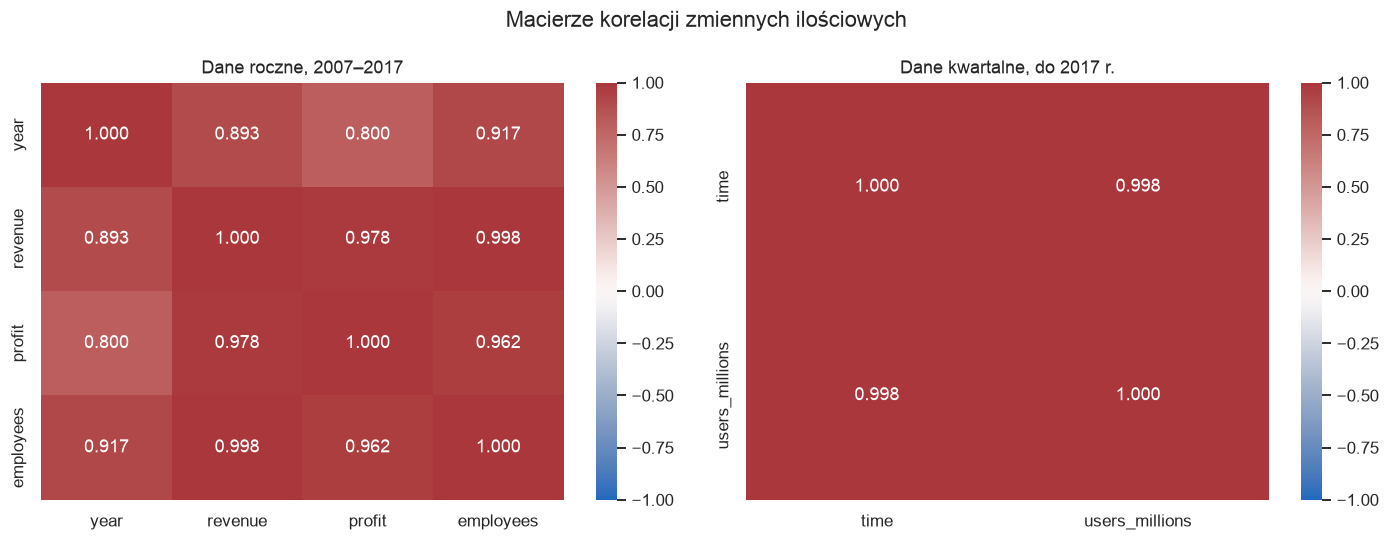

,year,revenue,profit,employees
year,1.000,0.893,0.800,0.917
revenue,0.893,1.000,0.978,0.998
profit,0.800,0.978,1.000,0.962
employees,0.917,0.998,0.962,1.000


,time,users_millions
time,1.000,0.998
users_millions,0.998,1.000


In [6]:
# Korelacje opisują współzmienność w próbie, nie dowodzą przyczynowości.
annual_corr = annual_train[["year", "revenue", "profit", "employees"]].corr()
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(annual_corr, annot=True, fmt=".3f", cmap="vlag", center=0, vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Dane roczne, 2007–2017")
user_corr = users_train[["time", "users_millions"]].corr()
sns.heatmap(user_corr, annot=True, fmt=".3f", cmap="vlag", center=0, vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Dane kwartalne, do 2017 r.")
fig.suptitle("Macierze korelacji zmiennych ilościowych")
plt.tight_layout()
plt.show()
display(annual_corr.round(3), user_corr.round(3))


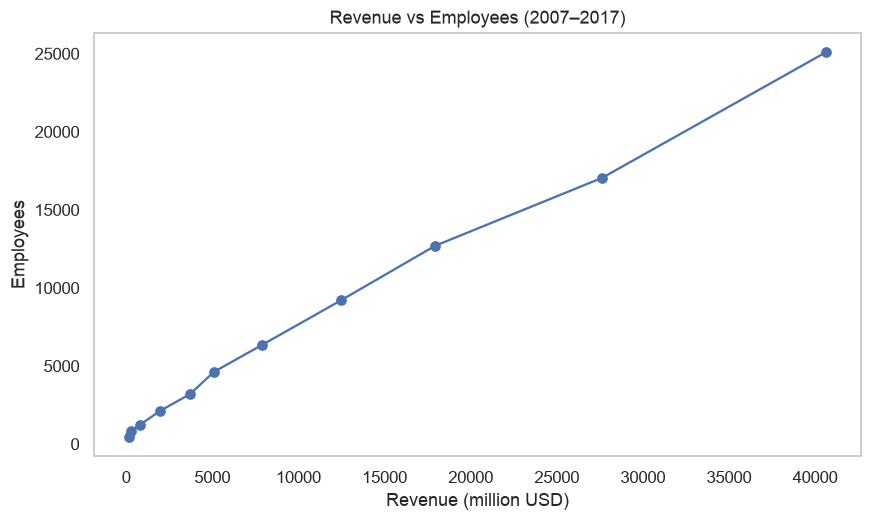

In [7]:
plt.figure(figsize=(9, 5))

plt.plot(
    annual_train["revenue"],
    annual_train["employees"],
    marker="o",
)

plt.xlabel("Revenue (million USD)")
plt.ylabel("Employees")
plt.title("Revenue vs Employees (2007–2017)")
plt.grid()
plt.show()

# Wstępne obserwacje

Na podstawie wykresu zależności przychodów i zatrudnienia można
zauważyć silną dodatnią zależność pomiędzy analizowanymi zmiennymi.

Wzrostowi przychodów towarzyszy wzrost zatrudnienia. Na podstawie
samego wykresu nie można jednak jednoznacznie rozstrzygnąć,
czy zależność ma charakter liniowy, czy kwadratowy.

W celu dokładniejszego określenia charakteru zależności zostaną
oszacowane i porównane oba modele regresji.

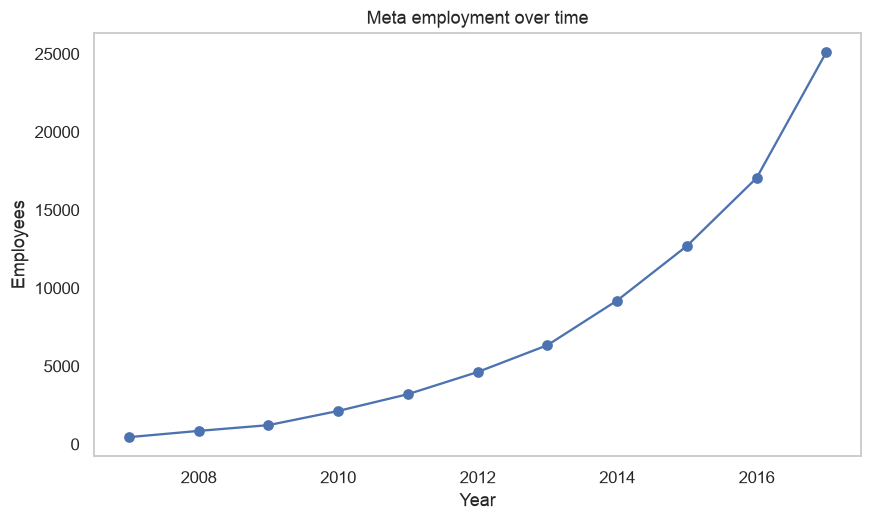

In [8]:
plt.figure(figsize=(9, 5))

plt.plot(
    annual_train["year"],
    annual_train["employees"],
    marker="o",
)

plt.xlabel("Year")
plt.ylabel("Employees")
plt.title("Meta employment over time")
plt.grid()
plt.show()

Wykres przedstawia zmianę liczby zatrudnionych pracowników
przedsiębiorstwa Meta w latach 2007–2017.

Widoczny jest ogólny trend wzrostowy zatrudnienia.
Obserwacja ta stanowi dodatkowe uzasadnienie
do zbadania zależności pomiędzy przychodami
a liczbą pracowników.

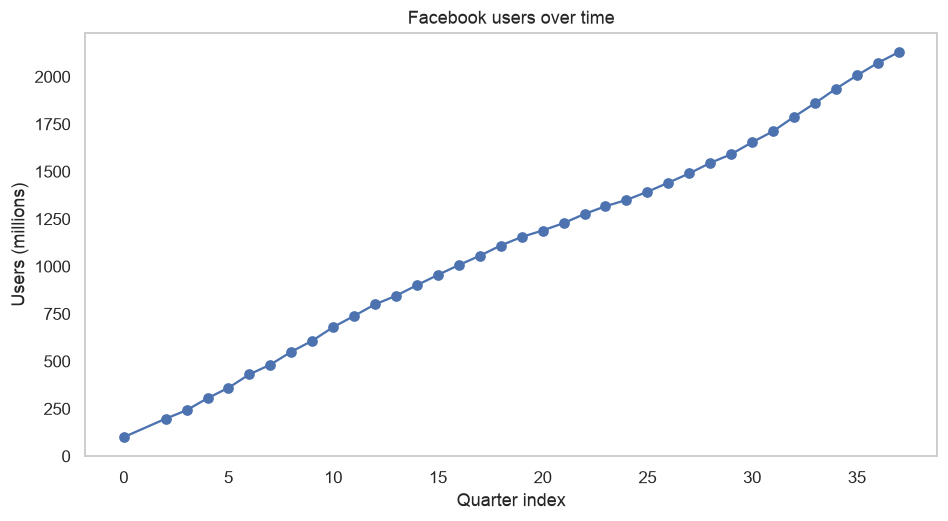

In [9]:
plt.figure(figsize=(10, 5))

plt.plot(
    users_train["time"],
    users_train["users_millions"],
    marker="o",
)

plt.xlabel("Quarter index")
plt.ylabel("Users (millions)")
plt.title("Facebook users over time")
plt.grid()
plt.show()

Wykres przedstawia kwartalną liczbę aktywnych użytkowników
Facebooka w okresie od III kwartału 2008 do IV kwartału 2017.

Widoczny jest długoterminowy trend wzrostowy.
W celu określenia charakteru tej zależności zostaną
porównane modele regresji liniowej i kwadratowej.

# Modele regresji i ich ocena

Analiza główna obejmuje **sześć modeli**: liniowy i kwadratowy dla każdej z trzech zależności (zatrudnienie–przychody, zysk–przychody, użytkownicy–czas). Dodatkowo w kwartalnej walidacji sprawdzamy efekty kwartału, krzywiznę i trend wykładniczy względem prostego trendu liniowego. Kandydatury dodatkowe pozostają poza prognozami testowymi, ponieważ nie poprawiają walidacji.

Dla każdej pary stosujemy tę samą kolejność: podsumowanie estymacji, miary dopasowania, wspólny wykres dopasowania, wspólna diagnostyka reszt, a następnie prognozy oraz ich ocena.

In [10]:
annual_train["revenue_b"] = (
    annual_train["revenue"] / 1000
)

annual_test["revenue_b"] = (
    annual_test["revenue"] / 1000
)

linear_model = smf.ols(
    "employees ~ revenue_b",
    data=annual_train,
).fit()

print(linear_model.summary())

                            OLS Regression Results                            
Dep. Variable:              employees   R-squared:                       0.995
Model:                            OLS   Adj. R-squared:                  0.995
Method:                 Least Squares   F-statistic:                     1866.
Date:                Sun, 08 Nov 2026   Prob (F-statistic):           9.53e-12
Time:                        18:03:59   Log-Likelihood:                -84.414
No. Observations:                  11   AIC:                             172.8
Df Residuals:                       9   BIC:                             173.6
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   1074.6305    229.039      4.692      0.0

### Wyniki modelu liniowego: zatrudnienie

Model ma postać $\hat{Y}=\hat{\beta}_0+\hat{\beta}_1X$, gdzie $Y$ to zatrudnienie, a $X$ to przychody w mld USD. Estymaty parametrów, ich błędy standardowe, testy t oraz test F są podane w podsumowaniu regresji. Współczynnik kierunkowy opisuje zmianę przewidywanego zatrudnienia przy wzroście przychodów o 1 mld USD; nie jest interpretowany przyczynowo.

### Testy parametrów modelu liniowego

Dla współczynników sprawdzamy $H_0: \beta_j=0$ wobec $H_1: \beta_j\ne0$ przy poziomie $\alpha=0{,}05$. Błędy standardowe, statystyki t i wartości p podsumowano w tabeli OLS. Model należy interpretować jako zależność opisową, nie przyczynową.

In [11]:
revenue_mean = annual_train["revenue_b"].mean()

annual_train["revenue_c"] = (
    annual_train["revenue_b"] - revenue_mean
)

annual_test["revenue_c"] = (
    annual_test["revenue_b"] - revenue_mean
)

quadratic_model = smf.ols(
    "employees ~ revenue_c + I(revenue_c ** 2)",
    data=annual_train,
).fit()

print(quadratic_model.summary())

                            OLS Regression Results                            
Dep. Variable:              employees   R-squared:                       0.997
Model:                            OLS   Adj. R-squared:                  0.997
Method:                 Least Squares   F-statistic:                     1582.
Date:                Sun, 08 Nov 2026   Prob (F-statistic):           4.05e-11
Time:                        18:03:59   Log-Likelihood:                -80.877
No. Observations:                  11   AIC:                             167.8
Df Residuals:                       8   BIC:                             168.9
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept          7924.3280    198.01

### Wyniki modelu kwadratowego: zatrudnienie

Model zawiera wycentrowane przychody $X_c=X-\bar X$ i ich kwadrat. Centrowanie ułatwia interpretację i ogranicza współliniowość składników. Podsumowanie regresji podaje estymaty, błędy standardowe, testy t i ogólny test F. O wyborze kształtu decydują również diagnostyka oraz błędy prognoz poza próbą.

In [12]:
def model_quality(model, name):
    return {
        "Model": name,
        "n": int(model.nobs),
        "R²": model.rsquared,
        "R² skorygowane": model.rsquared_adj,
        "Błąd standardowy reszt": np.sqrt(model.mse_resid),
        "F": model.fvalue,
        "p (F)": model.f_pvalue,
    }

def display_quality(table):
    view = table.copy()
    view["p (F)"] = view["p (F)"].map(lambda value: f"{value:.3e}")
    display(view.round(4))

employment_quality = pd.DataFrame([
    model_quality(linear_model, "Zatrudnienie: liniowy"),
    model_quality(quadratic_model, "Zatrudnienie: kwadratowy"),
])
display_quality(employment_quality)

,Model,n,R²,R² skorygowane,Błąd standardowy reszt,F,p (F)
0,Zatrudnienie: liniowy,11,0.9952,0.9947,575.6124,1866.2416,9.527e-12
1,Zatrudnienie: kwadratowy,11,0.9975,0.9968,442.6325,1581.6265,4.050e-11


### Porównanie dopasowania modeli

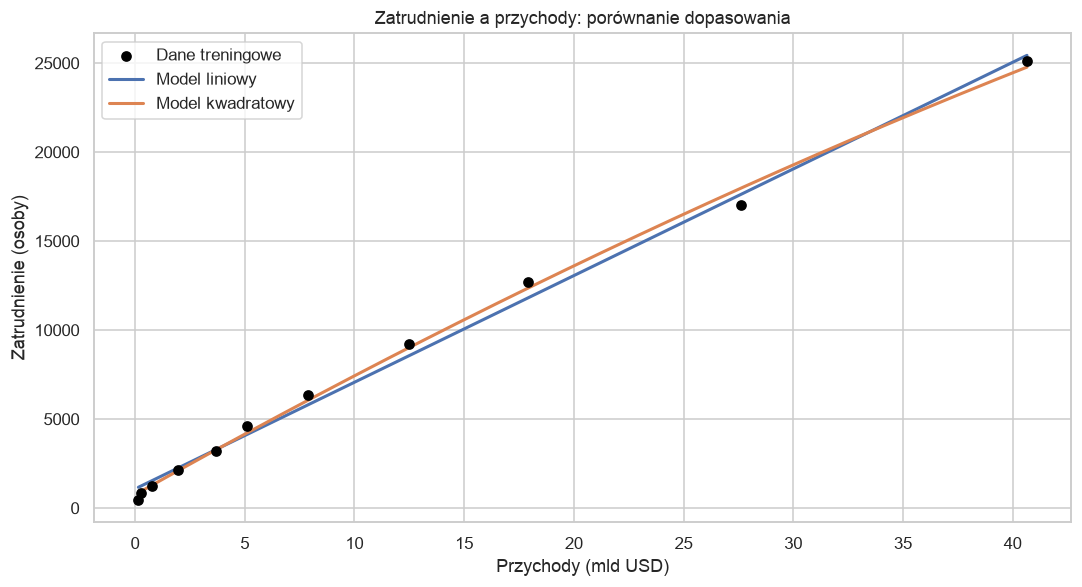

In [13]:
x_grid = np.linspace(annual_train["revenue_b"].min(), annual_train["revenue_b"].max(), 250)
grid = pd.DataFrame({"revenue_b": x_grid, "revenue_c": x_grid - revenue_mean})
plt.figure(figsize=(10, 5.5))
plt.scatter(annual_train["revenue_b"], annual_train["employees"], color="black", marker="o", label="Dane treningowe", zorder=3)
plt.plot(x_grid, linear_model.predict(grid), label="Model liniowy", color="C0", linewidth=2)
plt.plot(x_grid, quadratic_model.predict(grid), label="Model kwadratowy", color="C1", linewidth=2)
plt.xlabel("Przychody (mld USD)"); plt.ylabel("Zatrudnienie (osoby)")
plt.title("Zatrudnienie a przychody: porównanie dopasowania"); plt.legend(); plt.tight_layout(); plt.show()


### Porównanie diagnostyki reszt

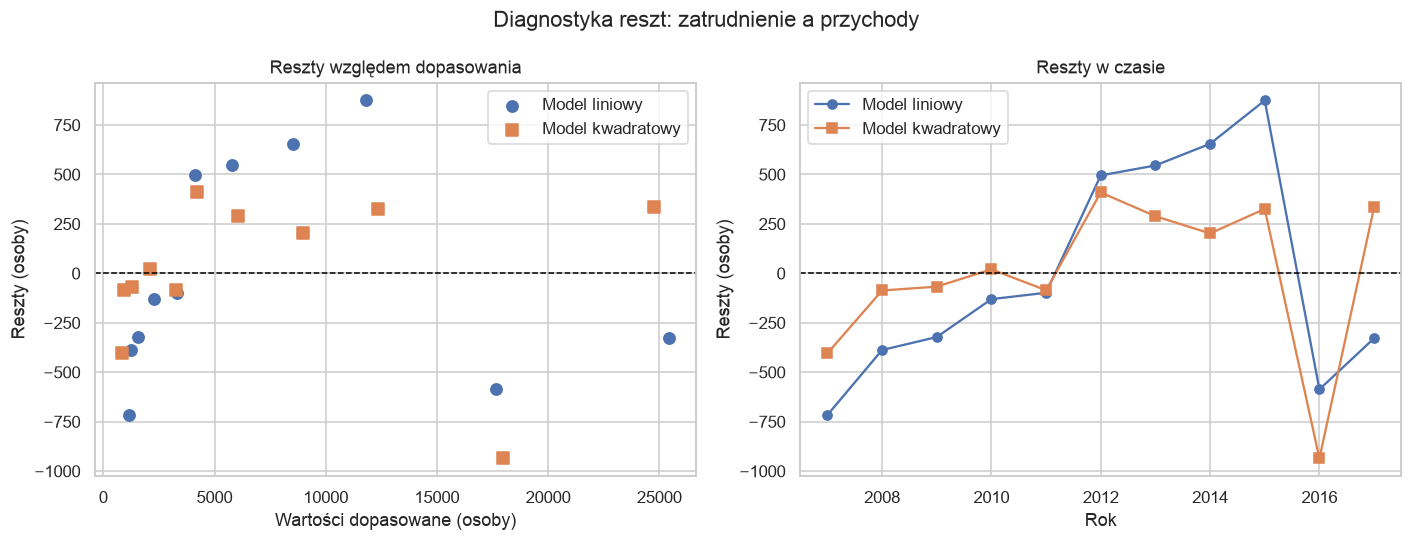

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for model, label, color, marker in [
    (linear_model, "Model liniowy", "C0", "o"),
    (quadratic_model, "Model kwadratowy", "C1", "s"),
]:
    axes[0].scatter(model.fittedvalues, model.resid, label=label, color=color, marker=marker, s=55)
    axes[1].plot(annual_train["year"], model.resid, label=label, color=color, marker=marker)
axes[0].axhline(0, color="black", linestyle="--", linewidth=1)
axes[0].set(xlabel="Wartości dopasowane (osoby)", ylabel="Reszty (osoby)", title="Reszty względem dopasowania")
axes[1].axhline(0, color="black", linestyle="--", linewidth=1)
axes[1].set(xlabel="Rok", ylabel="Reszty (osoby)", title="Reszty w czasie")
for ax in axes: ax.legend()
fig.suptitle("Diagnostyka reszt: zatrudnienie a przychody")
plt.tight_layout(); plt.show()

### Interpretacja diagnostyki reszt

W obu panelach porównujemy te same dwa modele. Losowy rozrzut wokół zera jest zgodny z prostym opisem regresyjnym; łuk może wskazywać brakującą nieliniowość, a długie serie reszt o tym samym znaku w czasie sugerują zależność błędów między okresami. To diagnostyka opisowa, a nie samodzielny test założeń.

# Predykcja i sprawdzanie jakości modeli

In [15]:
def forecast_metrics(actual, predicted):

    error = actual - predicted

    return {
        "ME": error.mean(),
        "MAE": np.abs(error).mean(),
        "RMSE": np.sqrt(np.mean(error ** 2)),
        "MAPE": (
            np.mean(
                np.abs(error / actual)
            ) * 100
        ),
    }
annual_test["pred_linear"] = (
    linear_model.predict(annual_test)
)

annual_test["pred_quadratic"] = (
    quadratic_model.predict(annual_test)
)

display(
    annual_test[
        [
            "year",
            "employees",
            "pred_linear",
            "pred_quadratic",
        ]
    ].round(2)
)

,year,employees,pred_linear,pred_quadratic
11,2018,35587.0,34531.86,31616.18
12,2019,44942.0,43435.13,37193.26
13,2020,58604.0,52583.47,41769.13
14,2021,71970.0,71735.79,47558.87
15,2022,86482.0,70944.87,47421.32
16,2023,67317.0,81423.99,48533.88
17,2024,74067.0,99640.98,46812.72
18,2025,78865.0,121490.22,38627.22


In [16]:
periods = {"2018–2020": (2018, 2020), "2021–2023": (2021, 2023), "2024–2025": (2024, 2025)}
for name, (start, end) in periods.items():
    part = annual_test[annual_test["year"].between(start, end)].dropna(subset=["employees"])
    print(f"\n{name} (n={len(part)})")
    if part.empty:
        print("Brak obserwacji w dostępnym zbiorze.")
        continue
    for label, pred in [("Liniowy", "pred_linear"), ("Kwadratowy", "pred_quadratic")]:
        print(label, forecast_metrics(part["employees"], part[pred]))



2018–2020 (n=3)
Liniowy {'ME': np.float64(2860.8435250544717), 'MAE': np.float64(2860.8435250544717), 'RMSE': np.float64(3634.588200425109), 'MAPE': np.float64(5.530367349396658)}
Kwadratowy {'ME': np.float64(9518.143951493435), 'MAE': np.float64(9518.143951493435), 'RMSE': np.float64(10942.627936605957), 'MAPE': np.float64(19.042065380511534)}

2021–2023 (n=3)
Liniowy {'ME': np.float64(554.7845699941341), 'MAE': np.float64(9959.446320813155), 'RMSE': np.float64(12116.994206896834), 'MAPE': np.float64(13.08241203039736)}
Kwadratowy {'ME': np.float64(27418.3093134246), 'MAE': np.float64(27418.3093134246), 'RMSE': np.float64(28719.595817024634), 'MAPE': np.float64(35.662407322592976)}

2024–2025 (n=2)
Liniowy {'ME': np.float64(-34099.60102484583), 'MAE': np.float64(34099.60102484583), 'RMSE': np.float64(35149.23887000429), 'MAPE': np.float64(44.28825442740204)}
Kwadratowy {'ME': np.float64(33746.033005183854), 'MAE': np.float64(33746.033005183854), 'RMSE': np.float64(34364.771876669445)

### Wnioski z predykcji zatrudnienia

Tabela błędów poniżej porównuje prognozy na każdym wymaganym okresie. Ponieważ modele otrzymują rzeczywiste przychody z lat testowych, wyniki mierzą prognozowanie zatrudnienia przy znanych przychodach.

### Wartości rzeczywiste i prognozowane: zatrudnienie

Wykres pokazuje część treningową, obserwacje testowe oraz obie prognozy. Warto pamiętać, że modele zatrudnienia otrzymują rzeczywiste przychody testowe, więc jest to prognoza warunkowa.

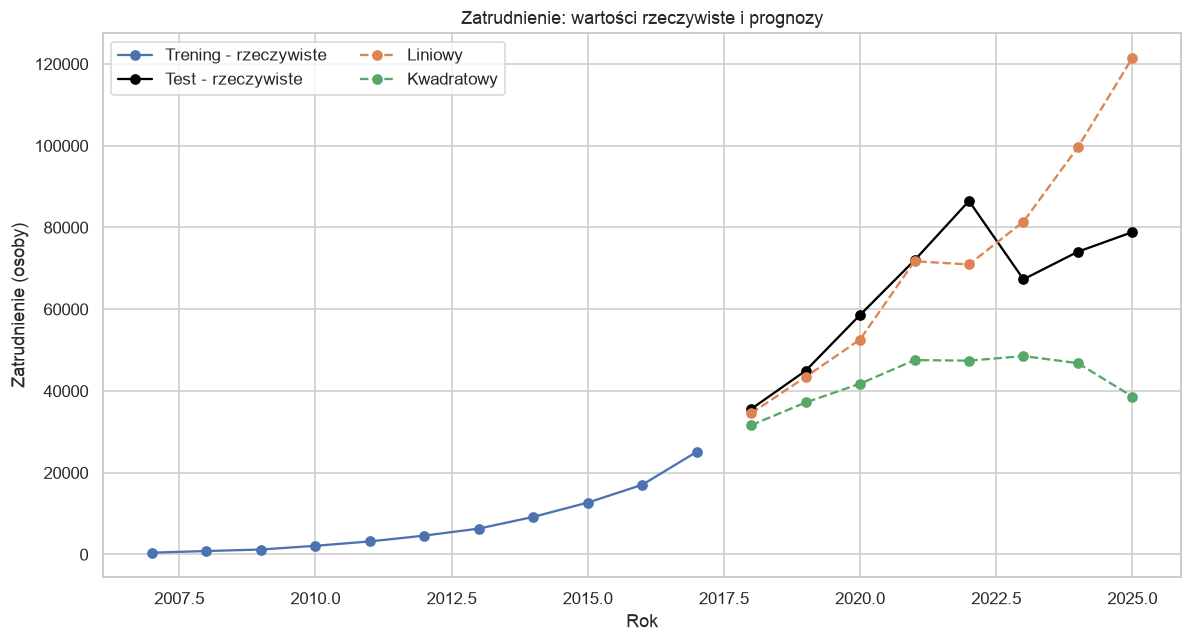

In [17]:
fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(annual_train["year"], annual_train["employees"], marker="o", label="Trening - rzeczywiste")
ax.plot(annual_test["year"], annual_test["employees"], marker="o", color="black", label="Test - rzeczywiste")
ax.plot(annual_test["year"], annual_test["pred_linear"], "--o", label="Liniowy")
ax.plot(annual_test["year"], annual_test["pred_quadratic"], "--o", label="Kwadratowy")
ax.set(xlabel="Rok", ylabel="Zatrudnienie (osoby)", title="Zatrudnienie: wartości rzeczywiste i prognozy")
ax.legend(ncol=2); plt.tight_layout(); plt.show()


# 2. Zysk a przychody

To dodatkowa relacja biznesowa bezpośrednio oparta na rocznych zmiennych z arkusza. Porównamy modele liniowy i kwadratowy na tych samych latach treningowych. Test 2018–2025 wykorzystuje rzeczywiste przychody jako predyktor, więc ocenia prognozę zysku warunkową względem znanych przychodów. Wnioski opisują asocjację, nie efekt przyczynowy.

In [18]:
profit_train = annual_train.dropna(subset=["revenue", "profit"]).copy()
profit_test = annual_test.dropna(subset=["revenue", "profit"]).copy()
profit_train["revenue_b"] = profit_train["revenue"] / 1000
profit_test["revenue_b"] = profit_test["revenue"] / 1000
profit_revenue_mean = profit_train["revenue_b"].mean()
profit_train["revenue_c"] = profit_train["revenue_b"] - profit_revenue_mean
profit_test["revenue_c"] = profit_test["revenue_b"] - profit_revenue_mean
profit_linear = smf.ols("profit ~ revenue_b", data=profit_train).fit()
profit_quadratic = smf.ols("profit ~ revenue_c + I(revenue_c ** 2)", data=profit_train).fit()
print("Model liniowy")
print(profit_linear.summary())
print("Model kwadratowy")
print(profit_quadratic.summary())
print("Test F modeli zagnieżdżonych (kwadratowy względem liniowego):", profit_quadratic.compare_f_test(profit_linear))


Model liniowy
                            OLS Regression Results                            
Dep. Variable:                 profit   R-squared:                       0.956
Model:                            OLS   Adj. R-squared:                  0.951
Method:                 Least Squares   F-statistic:                     194.1
Date:                Sun, 08 Nov 2026   Prob (F-statistic):           2.14e-07
Time:                        18:04:00   Log-Likelihood:                -91.987
No. Observations:                  11   AIC:                             188.0
Df Residuals:                       9   BIC:                             188.8
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   -874.1162    455.905     -

Błędy standardowe i testy t w podsumowaniach dotyczą poszczególnych parametrów; test F porównuje, czy składnik kwadratowy wnosi dodatkowe wyjaśnienie w próbie treningowej. Przy zaledwie 11 latach i trendzie wspólnym dla obu wielkości wyniki inferencji są orientacyjne.

In [19]:
profit_quality = pd.DataFrame([
    model_quality(profit_linear, "Zysk: liniowy"),
    model_quality(profit_quadratic, "Zysk: kwadratowy"),
])
display_quality(profit_quality)

,Model,n,R²,R² skorygowane,Błąd standardowy reszt,F,p (F)
0,Zysk: liniowy,11,0.9557,0.9508,1145.7624,194.0647,2.141e-07
1,Zysk: kwadratowy,11,0.9853,0.9816,700.4029,267.7050,4.697e-08


### Porównanie dopasowania modeli

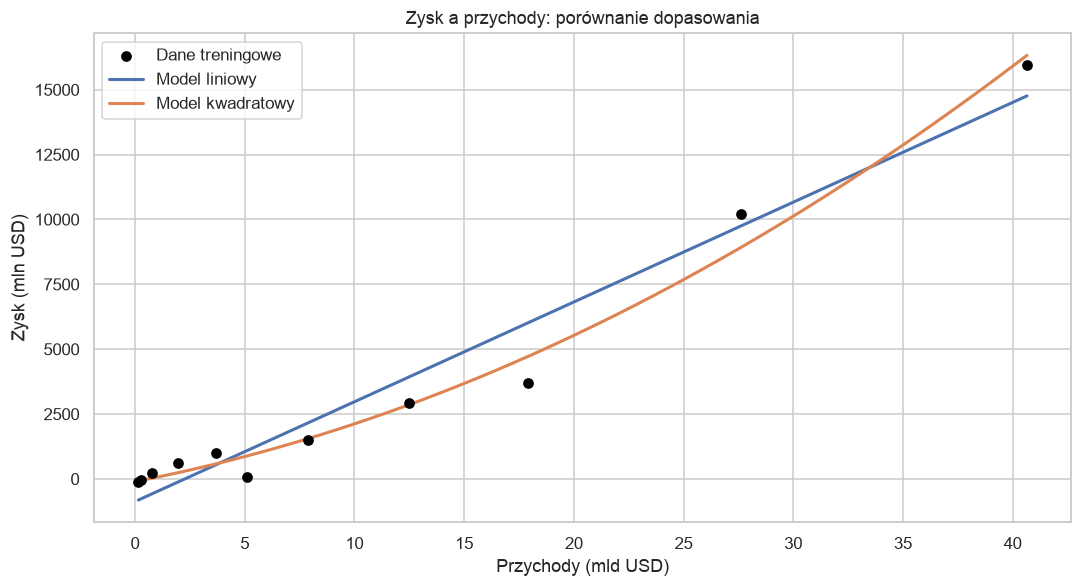

In [20]:
xp = np.linspace(profit_train["revenue_b"].min(), profit_train["revenue_b"].max(), 250)
gp = pd.DataFrame({"revenue_b": xp, "revenue_c": xp - profit_revenue_mean})
plt.figure(figsize=(10, 5.5))
plt.scatter(profit_train["revenue_b"], profit_train["profit"], color="black", marker="o", label="Dane treningowe", zorder=3)
plt.plot(xp, profit_linear.predict(gp), label="Model liniowy", color="C0", linewidth=2)
plt.plot(xp, profit_quadratic.predict(gp), label="Model kwadratowy", color="C1", linewidth=2)
plt.xlabel("Przychody (mld USD)"); plt.ylabel("Zysk (mln USD)")
plt.title("Zysk a przychody: porównanie dopasowania"); plt.legend(); plt.tight_layout(); plt.show()


### Porównanie diagnostyki reszt

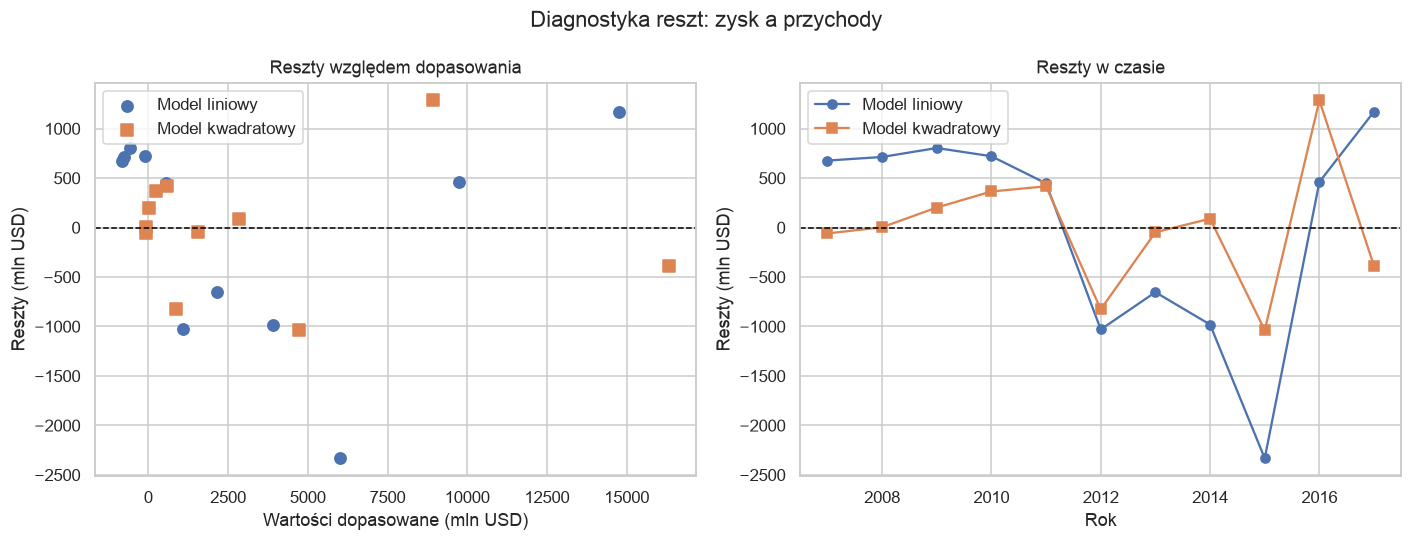

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for model, label, color, marker in [
    (profit_linear, "Model liniowy", "C0", "o"),
    (profit_quadratic, "Model kwadratowy", "C1", "s"),
]:
    axes[0].scatter(model.fittedvalues, model.resid, label=label, color=color, marker=marker, s=55)
    axes[1].plot(profit_train["year"], model.resid, label=label, color=color, marker=marker)
axes[0].axhline(0, color="black", linestyle="--", linewidth=1)
axes[0].set(xlabel="Wartości dopasowane (mln USD)", ylabel="Reszty (mln USD)", title="Reszty względem dopasowania")
axes[1].axhline(0, color="black", linestyle="--", linewidth=1)
axes[1].set(xlabel="Rok", ylabel="Reszty (mln USD)", title="Reszty w czasie")
for ax in axes: ax.legend()
fig.suptitle("Diagnostyka reszt: zysk a przychody")
plt.tight_layout(); plt.show()

### Interpretacja diagnostyki reszt

W obu modelach sprawdzamy wzorzec reszt względem dopasowania oraz roku. Krzywizna, zmienna rozpiętość albo serie błędów o jednym znaku wskazują, że same miary dopasowania mogą nie opisywać całej struktury danych. Przy 11 obserwacjach diagnostyka jest wskazówką, nie rozstrzygającym testem.

In [22]:
profit_test["pred_linear"] = profit_linear.predict(profit_test)
profit_test["pred_quadratic"] = profit_quadratic.predict(profit_test)
display(profit_test[["year", "profit", "pred_linear", "pred_quadratic"]].round(1))
for label, (start, end) in periods.items():
    part = profit_test[profit_test["year"].between(start, end)]
    if len(part):
        print(label, "n=", len(part), "liniowy", forecast_metrics(part["profit"], part["pred_linear"]),
              "kwadratowy", forecast_metrics(part["profit"], part["pred_quadratic"]))
    else:
        print(label, "brak obserwacji")


,year,profit,pred_linear,pred_quadratic
11,2018,22112.0,20601.4,27487.6
12,2019,18485.0,26316.2,41058.1
13,2020,29146.0,32188.4,57729.3
14,2021,39370.0,44481.9,101582.1
15,2022,23200.0,43974.2,99531.3
16,2023,39098.0,50700.5,128379.3
17,2024,62360.0,62393.6,187161.6
18,2025,60458.0,76418.2,272121.2


2018–2020 n= 3 liniowy {'ME': np.float64(-3121.0078467365893), 'MAE': np.float64(4128.069334830133), 'RMSE': np.float64(4928.362156711066), 'MAPE': np.float64(19.878442055685554)} kwadratowy {'ME': np.float64(-18843.992288576457), 'MAE': np.float64(18843.992288576457), 'RMSE': np.float64(21255.961399406933), 'MAPE': np.float64(81.49859294501945)}
2021–2023 n= 3 liniowy {'ME': np.float64(-12496.189990415152), 'MAE': np.float64(12496.189990415152), 'RMSE': np.float64(14051.292027367377), 'MAPE': np.float64(44.06784797561407)} kwadratowy {'ME': np.float64(-75941.54389340404), 'MAE': np.float64(75941.54389340404), 'RMSE': np.float64(76741.88860497114), 'MAPE': np.float64(238.46189524057277)}
2024–2025 n= 2 liniowy {'ME': np.float64(-7996.937886727163), 'MAE': np.float64(7996.937886727163), 'RMSE': np.float64(11285.61350483312), 'MAPE': np.float64(13.226413075392554)} kwadratowy {'ME': np.float64(-168232.43575677404), 'MAE': np.float64(168232.43575677404), 'RMSE': np.float64(173748.05642595

### Rzeczywisty zysk i prognozy poza próbą

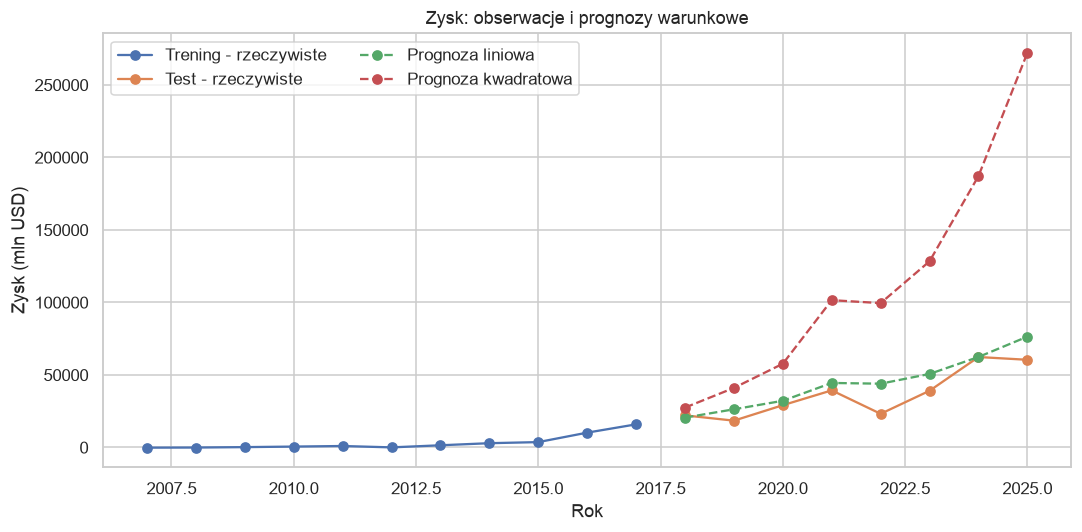

In [23]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(profit_train["year"], profit_train["profit"], marker="o", label="Trening - rzeczywiste")
ax.plot(profit_test["year"], profit_test["profit"], marker="o", label="Test - rzeczywiste")
ax.plot(profit_test["year"], profit_test["pred_linear"], "--o", label="Prognoza liniowa")
ax.plot(profit_test["year"], profit_test["pred_quadratic"], "--o", label="Prognoza kwadratowa")
ax.set(xlabel="Rok", ylabel="Zysk (mln USD)", title="Zysk: obserwacje i prognozy warunkowe")
ax.legend(ncol=2); plt.tight_layout(); plt.show()


Widzimy wyraźnie, że prognoza liniowa lepiej przewidywała zależnośc roku z zyskiem.

# 3. Użytkownicy Facebooka a czas

Dla danych kwartalnych porównujemy główny zestaw dwóch modeli: trend liniowy i kwadratowy, estymowane na obserwacjach do 2017 r. Późniejsze kwartały służą do oceny prognoz. Arkusz nie zawiera danych kwartalnych na lata 2024–2025.

In [24]:
users_linear = smf.ols(
    "users_millions ~ time",
    data=users_train,
).fit()

print(users_linear.summary())

                            OLS Regression Results                            
Dep. Variable:         users_millions   R-squared:                       0.996
Model:                            OLS   Adj. R-squared:                  0.996
Method:                 Least Squares   F-statistic:                     8516.
Date:                Sun, 08 Nov 2026   Prob (F-statistic):           2.18e-43
Time:                        18:04:00   Log-Likelihood:                -185.28
No. Observations:                  37   AIC:                             374.6
Df Residuals:                      35   BIC:                             377.8
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    122.9207     12.432      9.888      0.0

In [25]:
time_mean = users_train["time"].mean()

users_train["time_c"] = (
    users_train["time"] - time_mean
)

users_test["time_c"] = (
    users_test["time"] - time_mean
)

users_quadratic = smf.ols(
    "users_millions ~ time_c + I(time_c ** 2)",
    data=users_train,
).fit()

print(users_quadratic.summary())

                            OLS Regression Results                            
Dep. Variable:         users_millions   R-squared:                       0.996
Model:                            OLS   Adj. R-squared:                  0.996
Method:                 Least Squares   F-statistic:                     4171.
Date:                Sun, 08 Nov 2026   Prob (F-statistic):           2.21e-41
Time:                        18:04:00   Log-Likelihood:                -185.13
No. Observations:                  37   AIC:                             376.3
Df Residuals:                      34   BIC:                             381.1
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept       1125.2469      9.213    122.

In [26]:
# Porównanie jakości modeli użytkowników

users_quality = pd.DataFrame([
    model_quality(users_linear, "Użytkownicy: liniowy"),
    model_quality(users_quadratic, "Użytkownicy: kwadratowy"),
])

display_quality(users_quality)

,Model,n,R²,R² skorygowane,Błąd standardowy reszt,F,p (F)
0,Użytkownicy: liniowy,37,0.9959,0.9958,37.2085,8515.5442,2.182e-43
1,Użytkownicy: kwadratowy,37,0.9959,0.9957,37.5964,4170.5186,2.210e-41


### Porównanie dopasowania modeli

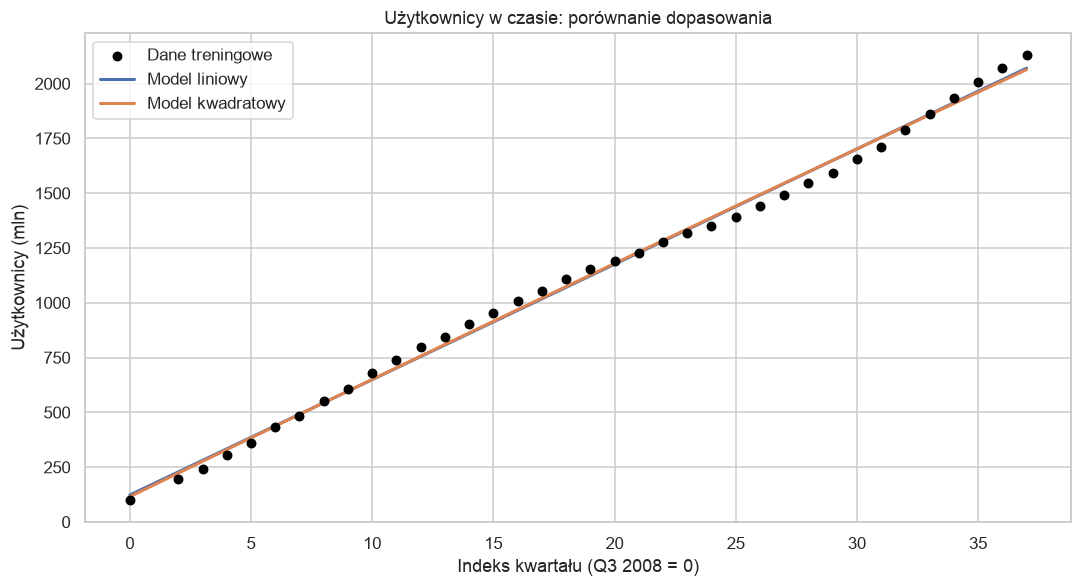

In [27]:
tu = np.linspace(users_train["time"].min(), users_train["time"].max(), 300)
du = pd.DataFrame({"time": tu, "time_c": tu - time_mean})
plt.figure(figsize=(10, 5.5))
plt.scatter(users_train["time"], users_train["users_millions"], color="black", marker="o", s=30, label="Dane treningowe", zorder=3)
plt.plot(tu, users_linear.predict(du), label="Model liniowy", color="C0", linewidth=2)
plt.plot(tu, users_quadratic.predict(du), label="Model kwadratowy", color="C1", linewidth=2)
plt.xlabel("Indeks kwartału (Q3 2008 = 0)"); plt.ylabel("Użytkownicy (mln)")
plt.title("Użytkownicy w czasie: porównanie dopasowania"); plt.legend(); plt.tight_layout(); plt.show()


### Dlaczego oba dopasowania wyglądają prawie liniowo?

Na wykresie krzywe modelu liniowego i kwadratowego niemal się pokrywają, a zmiana liczby użytkowników w próbie wygląda prawie jak linia prosta. To zgadza się z wynikiem modelu kwadratowego: estymata przy $time_c^2$ wynosi $-0{,}0315$ (SE $=0{,}059$, $t=-0{,}531$, $p=0{,}599$; 95% przedział ufności: $[-0{,}152;\ 0{,}089]$). Przy poziomie $0{,}05$ nie odrzucamy $H_0:\beta_2=0$; przedział obejmuje zero, więc dane nie dają podstaw, by stwierdzić istotną krzywiznę.

Nie oznacza to, że udowodniliśmy, iż składnik kwadratowy jest dokładnie równy zero. W tym zbiorze prostszy model liniowy jest wystarczającym, bardziej oszczędnym opisem trendu. Wniosek z testu t pozostaje ostrożny, ponieważ reszty są silnie autokorelacyjne.

### Porównanie diagnostyki reszt

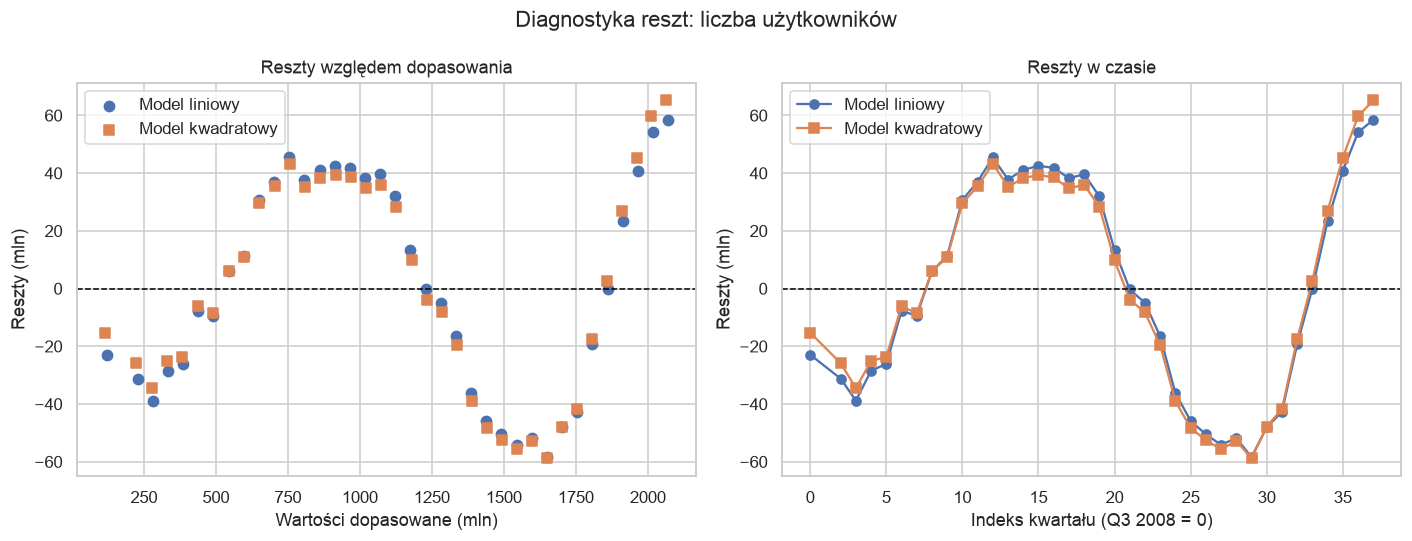

Durbin–Watson: liniowy = 0.1 ; kwadratowy = 0.103


In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for model, label, color, marker in [
    (users_linear, "Model liniowy", "C0", "o"),
    (users_quadratic, "Model kwadratowy", "C1", "s"),
]:
    axes[0].scatter(model.fittedvalues, model.resid, label=label, color=color, marker=marker, s=45)
    axes[1].plot(users_train["time"], model.resid, label=label, color=color, marker=marker)
axes[0].axhline(0, color="black", linestyle="--", linewidth=1)
axes[0].set(xlabel="Wartości dopasowane (mln)", ylabel="Reszty (mln)", title="Reszty względem dopasowania")
axes[1].axhline(0, color="black", linestyle="--", linewidth=1)
axes[1].set(xlabel="Indeks kwartału (Q3 2008 = 0)", ylabel="Reszty (mln)", title="Reszty w czasie")
for ax in axes: ax.legend()
fig.suptitle("Diagnostyka reszt: liczba użytkowników")
plt.tight_layout(); plt.show()
print("Durbin–Watson: liniowy =", round(durbin_watson(users_linear.resid), 3),
      "; kwadratowy =", round(durbin_watson(users_quadratic.resid), 3))

### Interpretacja diagnostyki reszt

Oba modele użytkowników wykazują podobny łuk względem wartości dopasowanych. W czasie widoczne są długie serie reszt o tym samym znaku: dodatnie w środku szeregu, ujemne później i ponownie dodatnie pod koniec. Składnik kwadratowy nie usuwa tego wzorca. Niski Durbin–Watson wskazuje na silną dodatnią autokorelację, więc klasyczne błędy standardowe i testy istotności należy interpretować ostrożnie.

### Testy parametrów modeli kwartalnych

Dla każdego parametru testujemy $H_0: \beta_j=0$ przy poziomie $\alpha=0{,}05$. Błędy standardowe, statystyki t i wartości p znajdują się w podsumowaniach OLS. Klasyczne testy zakładają niezależność błędów; diagnostyka poniżej pokazuje, że to założenie jest problematyczne dla tego szeregu.

### Testy F i błędy standardowe

Każda tabela jakości pokazuje liczebność, miary dopasowania, błąd standardowy reszt oraz test F. Pełne podsumowania OLS zawierają błędy standardowe, statystyki t i wartości p dla parametrów. Klasyczną inferencję dla danych kwartalnych ogranicza autokorelacja reszt.

### Ograniczenia modeli kwartalnych

Autokorelacja ogranicza wiarygodność klasycznych testów t i F oraz przedziałów opartych na błędach standardowych OLS. Modele pozostają użytecznymi opisami trendu i prognozami bazowymi, ale nie są pełnym modelem szeregów czasowych.

### Czy kwartał lub wykładniczy trend poprawia prognozowanie?

Dodatkowe warianty są oceniane przez chronologiczny podział wewnątrz okresu treningowego: dane do 2014 r. służą do estymacji, a lata 2015–2017 do walidacji. Kwartał wchodzi jako zmienna kategoryczna. Porównujemy prognozowane wartości na oryginalnej skali użytkowników; model wykładniczy estymuje logarytm użytkowników i daje prognozę medianową po eksponentacji. Test F dla kwartałów jest klasyczny i przy autokorelacji stanowi jedynie wskazówkę.

In [29]:
users_fit = users_train[users_train["year"] <= 2014].copy()
users_valid = users_train[users_train["year"].between(2015, 2017)].copy()
val_linear = smf.ols("users_millions ~ time", data=users_fit).fit()
val_seasonal = smf.ols("users_millions ~ time + C(quarter_num)", data=users_fit).fit()
val_quadratic = smf.ols("users_millions ~ time + I(time ** 2)", data=users_fit).fit()
users_fit["log_users"] = np.log(users_fit["users_millions"])
val_exponential = smf.ols("log_users ~ time", data=users_fit).fit()
validation = pd.DataFrame({
    "Model": ["Liniowy", "Trend + kwartał", "Kwadratowy", "Wykładniczy (log-liniowy)"],
    "RMSE 2015–2017": [
        np.sqrt(mean_squared_error(users_valid["users_millions"], val_linear.predict(users_valid))),
        np.sqrt(mean_squared_error(users_valid["users_millions"], val_seasonal.predict(users_valid))),
        np.sqrt(mean_squared_error(users_valid["users_millions"], val_quadratic.predict(users_valid))),
        np.sqrt(mean_squared_error(users_valid["users_millions"], np.exp(val_exponential.predict(users_valid)))),
    ],
})
display(validation.sort_values("RMSE 2015–2017").round(2))
print("Test F: trend + kwartał vs trend liniowy:", val_seasonal.compare_f_test(val_linear))
print("Błędy standardowe modelu sezonowego:")
display(val_seasonal.summary2().tables[1][["Coef.", "Std.Err.", "t", "P>|t|"]].round(4))


,Model,RMSE 2015–2017
0,Liniowy,52.64
1,Trend + kwartał,54.16
2,Kwadratowy,173.46
3,Wykładniczy (log-liniowy),1928.64


Test F: trend + kwartał vs trend liniowy: (np.float64(0.13596114700806228), np.float64(0.9374080245512237), np.float64(3.0))
Błędy standardowe modelu sezonowego:


,Coef.,Std.Err.,t,P>|t|
Intercept,123.9265,17.3678,7.1354,0.0000
C(quarter_num)[T.2],-4.3256,19.0240,-0.2274,0.8224
C(quarter_num)[T.3],-8.5476,18.3106,-0.4668,0.6457
C(quarter_num)[T.4],-11.3100,19.2000,-0.5891,0.5624
time,53.4922,0.9171,58.3301,0.0000


W walidacji 2015–2017 model z kwartałami uzyskał RMSE 54,16 mln, nieco gorzej niż sam trend liniowy (52,64 mln). Test F dla dodatkowych zmiennych kwartalnych daje p=0,937. W tych danych nie ma uzasadnienia, by zachować efekty sezonowe. Model kwadratowy (RMSE 173,46 mln) i wykładniczy (RMSE 1 928,64 mln) również wypadają gorzej w tym podokresie. Nie dodajemy ich do prognoz testowych. Klasyczny test F i walidacja obejmują krótki szereg, a autokorelacja ogranicza siłę wniosków.

In [30]:
# Predykcja kwartalnej liczby użytkowników

users_test["pred_linear"] = users_linear.predict(
    users_test
)

users_test["pred_quadratic"] = users_quadratic.predict(
    users_test
)

display(
    users_test[
        [
            "quarter",
            "year",
            "users_millions",
            "pred_linear",
            "pred_quadratic",
        ]
    ].round(2)
)

,quarter,year,users_millions,pred_linear,pred_quadratic
37,Q1 '18,2018,2196.0,2123.17,2115.28
38,Q2 '18,2018,2234.0,2175.81,2166.69
39,Q3 '18,2018,2271.0,2228.44,2218.02
40,Q4 '18,2018,2320.0,2281.08,2269.30
41,Q1 '19,2019,2375.0,2333.72,2320.51
42,Q2 '19,2019,2414.0,2386.36,2371.66
43,Q3 '19,2019,2449.0,2439.00,2422.75
44,Q4 '19,2019,2498.0,2491.63,2473.77
45,Q1 '20,2020,2603.0,2544.27,2524.73
46,Q2 '20,2020,2701.0,2596.91,2575.63


In [31]:
user_periods = {"2018–2020": (2018, 2020), "2021–2023": (2021, 2023), "2024–2025": (2024, 2025)}
for name, (start, end) in user_periods.items():
    part = users_test[users_test["year"].between(start, end)].dropna(subset=["users_millions"])
    print(f"\n{name} (n={len(part)})")
    if part.empty:
        print("Brak kwartalnych danych użytkowników w dostępnym zbiorze.")
        continue
    for label, pred in [("Liniowy", "pred_linear"), ("Kwadratowy", "pred_quadratic")]:
        print(label, forecast_metrics(part["users_millions"], part[pred]))



2018–2020 (n=12)
Liniowy {'ME': np.float64(53.82268760242323), 'MAE': np.float64(53.82268760242323), 'RMSE': np.float64(61.9676484655932), 'MAPE': np.float64(2.1516830337397526)}
Kwadratowy {'ME': np.float64(69.66140452339876), 'MAE': np.float64(69.66140452339876), 'RMSE': np.float64(77.20984443551792), 'MAPE': np.float64(2.7808495670532483)}

2021–2023 (n=12)
Liniowy {'ME': np.float64(-86.5009781876859), 'MAE': np.float64(125.76950976282171), 'RMSE': np.float64(149.07085838345813), 'MAPE': np.float64(4.2068146807717035)}
Kwadratowy {'ME': np.float64(-47.50515676288645), 'MAE': np.float64(107.58029780669237), 'RMSE': np.float64(123.04327784116482), 'MAPE': np.float64(3.6119077337871097)}

2024–2025 (n=0)
Brak kwartalnych danych użytkowników w dostępnym zbiorze.


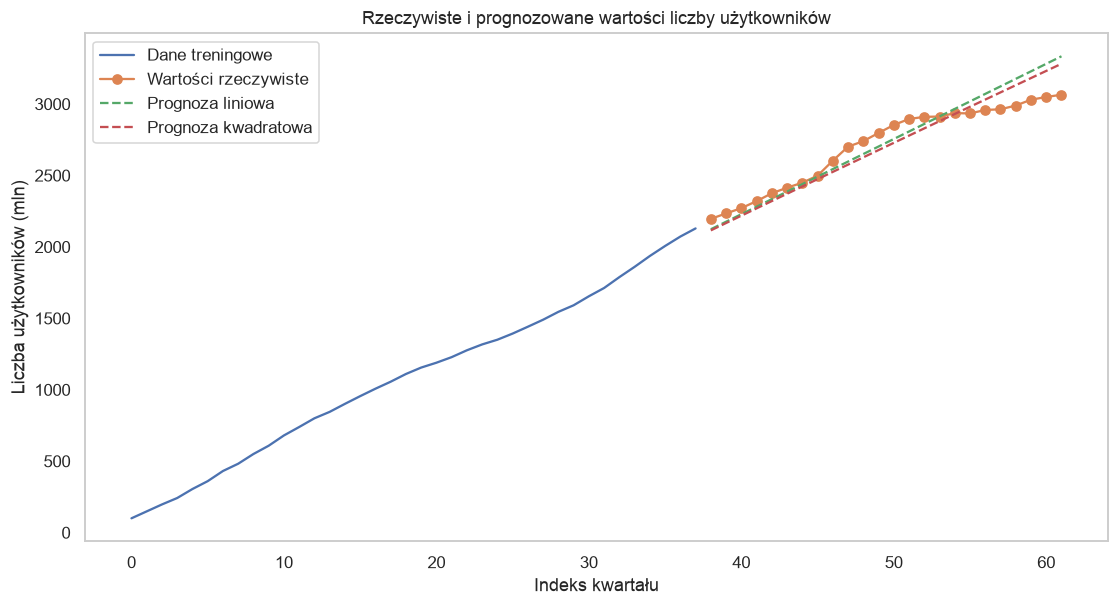

In [32]:
# Porównanie rzeczywistych i prognozowanych wartości

plt.figure(figsize=(12, 6))

plt.plot(
    users_train["time"],
    users_train["users_millions"],
    label="Dane treningowe",
)

plt.plot(
    users_test["time"],
    users_test["users_millions"],
    label="Wartości rzeczywiste",
    marker="o",
)

plt.plot(
    users_test["time"],
    users_test["pred_linear"],
    label="Prognoza liniowa",
    linestyle="--",
)

plt.plot(
    users_test["time"],
    users_test["pred_quadratic"],
    label="Prognoza kwadratowa",
    linestyle="--",
)

plt.xlabel("Indeks kwartału")
plt.ylabel("Liczba użytkowników (mln)")
plt.title("Rzeczywiste i prognozowane wartości liczby użytkowników")

plt.legend()
plt.grid()
plt.show()

Wykres dopasowania do próby pokazuje, że krzywe obu modeli niemal się pokrywają i są bliskie linii prostej. Na wykresie testowym prognozy również są prawie prostoliniowe i zbliżone do siebie, ale rzeczywista liczba użytkowników pod koniec szeregu wyhamowuje. Zgodnie z miarami błędów model kwadratowy uzyskał nieco mniejszy MAPE w latach 2021–2023 (3,61% wobec 4,21%), natomiast w latach 2018–2020 lepszy był liniowy (2,15% wobec 2,78%). Wizualne podobieństwo modeli nie oznacza identycznych błędów prognoz.

### Wnioski z predykcji liczby użytkowników

Porównanie błędów predykcji wykazało, że model liniowy osiągnął lepsze wyniki w okresie 2018–2020. Wartość MAPE wyniosła wtedy 2,15% dla modelu liniowego oraz 2,78% dla modelu kwadratowego.

W okresie 2021–2023 model kwadratowy uzyskał mniejsze błędy predykcji. Wartość MAPE wyniosła 3,61%, podczas gdy dla modelu liniowego osiągnęła 4,21%.

Różnice pomiędzy modelami są stosunkowo niewielkie. Należy jednak pamiętać o silnej autokorelacji reszt, która ogranicza wiarygodność klasycznej inferencji statystycznej.

Dane kwartalne kończą się na IV kwartale 2023 roku, dlatego nie jest możliwa weryfikacja predykcji dla lat 2024–2025.

# Podsumowanie i wnioski końcowe

Porównano sześć modeli głównych: po dwa (liniowy i kwadratowy) dla zatrudnienia względem przychodów, zysku względem przychodów oraz użytkowników względem czasu. Przeanalizowano roczne dane Meta oraz kwartalne dane użytkowników Facebooka, zachowując chronologiczny podział: modele główne estymowano do 2017 r., a późniejsze lata służyły do oceny predykcji. Dane roczne obejmują lata 2018–2025; dane kwartalne użytkowników kończą się w 2023 r.

Dla zatrudnienia porównano zależność liniową i kwadratową od przychodów. Chociaż model kwadratowy ma lepsze dopasowanie w próbie treningowej, same miary dopasowania nie rozstrzygają o prognozowaniu. Predykcje wykorzystują rzeczywiste przychody z okresu testowego, a więc są warunkowe.

Dodatkowa analiza zysku i przychodów wskazuje, że model kwadratowy ma lepsze dopasowanie treningowe, lecz na odłożonych okresach jego prognozy szybko stają się zbyt wysokie. Model liniowy jest wyraźnie stabilniejszy w testowanych zakresach; również tutaj nie należy interpretować relacji jako przyczynowej.

Dla liczby użytkowników model liniowy i kwadratowy mają zbliżone dopasowanie, a składnik kwadratowy nie jest istotny według klasycznego testu t. Diagnostyka ujawnia wyraźne wzorce reszt w czasie i dodatnią autokorelację, zatem klasyczne błędy standardowe i testy mogą być zbyt optymistyczne. W chronologicznej walidacji na latach 2015–2017 efekty kwartału nie poprawiły prognozy (RMSE 54,16 wobec 52,64 mln; test F p=0,937). Kandydat wykładniczy wypadł dużo słabiej, więc oba rozszerzenia odrzucono.

Modele użytkowników można oceniać dla okresów 2018–2020 i 2021–2023. Dla lat 2024–2025 arkusz nie zawiera kwartalnych obserwacji użytkowników, dlatego nie przedstawiono tam wyniku testowego. Wnioski z całej analizy należy opierać łącznie na parametrach, ich błędach standardowych, testach, diagnostyce reszt i błędach prognozy, z uwzględnieniem małej liczby rocznych obserwacji oraz autokorelacji danych kwartalnych.
